Nesta atividade, você implementará um agente baseado no algoritmo REINFORCE, utilizando uma **política linear com softmax**. Você será responsável por definir e inicializar os pesos da política, calcular o gradiente da função objetivo e realizar a atualização dos parâmetros ao longo do treinamento.

Siga as instruções abaixo para implementar seu agente:

1. Implemente o método `__init__` que inicializa um novo agente. Ele deve receber como parâmetros o espaço de observações, o espaço de ações, a taxa de aprendizado $\alpha$, e o fator de desconto $\gamma$. Inicialize os pesos do modelo na variável `self.weights`.
2. Implemente o método `softmax`, que recebe um vetor de preferências (logits) $z = (z_1,\dotsc,z_K) \in \mathbb{R}^K$ e retorna as probabilidades de cada ação segundo a função softmax $\sigma(z)_i = \frac{e^{z_i}}{\sum_{j=1}^{K} e^{z_j}}$, para $i = 1, \dotsc, K.$
3. Implemente o método `choose_action`, responsável por escolher uma ação a partir de um estado observado.
4. Implemente o método `learn`, que atualiza os pesos do agente com base na experiência obtida durante a interação com o ambiente.
5. Implemente o método `train`, que executa o loop de treinamento do algoritmo REINFORCE. O ambiente de treinamento e o número de episódios devem ser fornecidos como parâmetros de entrada. O método deve retornar uma lista com a soma das recompensas obtidas ao longo de cada episódio.

In [ ]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch
import torch.optim as optim
from collections import deque
import random

In [ ]:
class QNetwork(nn.Module):
    def __init__(self, state_dim, num_actions):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, num_actions),
        )

    def forward(self, state):
        return self.layers(state)

In [ ]:
class DQNAgent:
    def __init__(
        self,
        observation_space,
        action_space,
        alpha,
        gamma,
        buffer_size,
        batch_size,
        target_update_interval,
        epsilon_initial,
        epsilon_decay,
        epsilon_min,
    ):
        self.observation_space = observation_space
        self.action_space = action_space

        self.state_dim = observation_space.shape[0]
        self.num_actions = action_space.n

        self.alpha = alpha
        self.gamma = gamma
        self.batch_size = batch_size
        self.target_update_interval = target_update_interval

        self.epsilon = epsilon_initial
        self.epsilon_decay = epsilon_decay
        self.epsilon_min = epsilon_min

        self.replay_buffer = deque(maxlen=buffer_size)
        self.total_steps = 0

        #rede principal e rede alvo começam com os mesmos pesos
        self.action_value = QNetwork(self.state_dim, self.num_actions)
        self.target = QNetwork(self.state_dim, self.num_actions)
        self.target.load_state_dict(self.action_value.state_dict())
        #não treinamos target diretamente apenas atualizmaos seus pesos com a action_value
        self.target.requires_grad_(False)
        self.target.eval()

        #apenas a rede principal é atualizada pelo otimizador
        self.optimizer = optim.Adam(self.action_value.parameters(), lr=self.alpha)
        self.loss_fn = nn.MSELoss()
        self.current_step = 0 


    def choose_action(self, state):
        choose_policy_action =  np.random.choice([1, 0], p=[1 - self.epsilon, self.epsilon])

        if choose_policy_action:
            state_tensor = torch.as_tensor(state, dtype=torch.float32)
            with torch.no_grad():
                q_values = self.action_value(state_tensor)

            action = q_values.argmax().item()

        else:
            action = self.action_space.sample() 
        return action

    def learn(self):
        if len(self.replay_buffer) < self.batch_size:
            return 
        batch = random.sample(self.replay_buffer, self.batch_size )

        predictions = []
        targets = []

        for transition in batch:
            state, action, reward, next_state, terminal = transition
            state_tensor = torch.as_tensor(state, dtype=torch.float32)
            next_state_tensor = torch.as_tensor(next_state, dtype=torch.float32)

            #vemos a predição da action_value
            prediction = self.action_value(state_tensor)[action]
            predictions.append(prediction)

            with torch.no_grad():
                target = torch.tensor(reward, dtype=torch.float32)
                #calculamos o alvo recompensa + valor futuro descontado estimado pela rede alvo
                if not terminal:
                    max_next_q = self.target(next_state_tensor).max()
                    target += self.gamma * max_next_q

            targets.append(target)
        predictions = torch.stack(predictions)
        targets = torch.stack(targets)

        loss = self.loss_fn(predictions, targets)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        

    def train(self, env, episodes):
        rewards = []
        for _ in range(episodes):
            state, _ = env.reset()
            trajectories = []
            action = self.choose_action(state)
            done = False
            total_reward = 0
            while not done:
                next_state, reward, terminated, truncated, _ = env.step(action)
                trajectories.append((state, action, reward))

                done = terminated or truncated
                next_action = self.choose_action(next_state)
                state = next_state
                action = next_action
                total_reward += reward
            self.learn(trajectories)
            rewards.append(total_reward)
        return rewards

        

In [ ]:
env = gym.make("LunaLander-v3")

reinfore_agent = ReinforceAgent(env.observation_space,env.action_space, alpha = 0.001, gamma= 1)
reinforce_returns = reinfore_agent.train(env, episodes = 2000)
env.close()

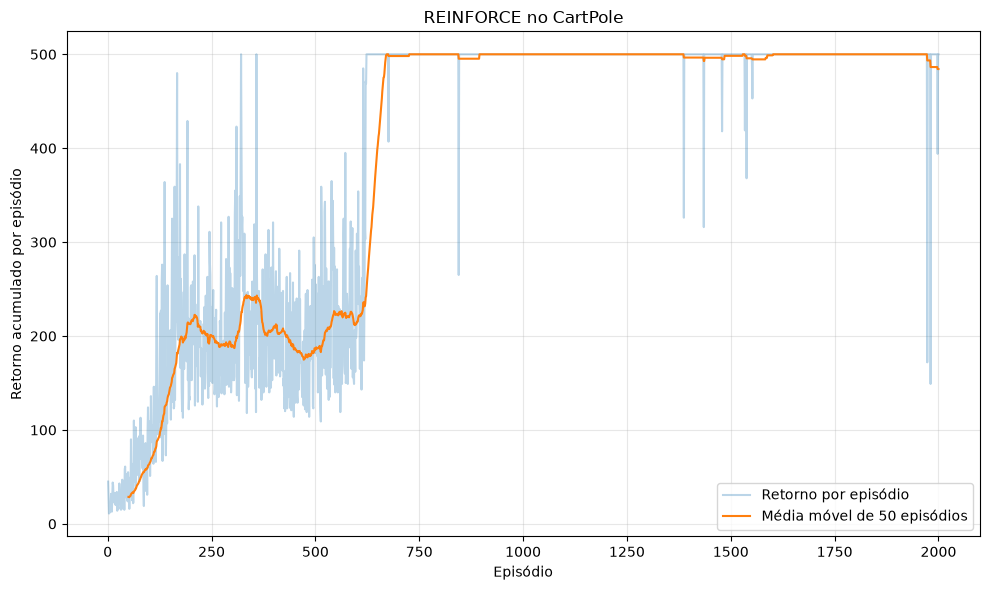

In [24]:
window = 50
returns = np.asarray(reinforce_returns, dtype=float)
episodes = np.arange(1, len(returns) + 1)
moving_average = np.convolve(returns, np.ones(window) / window, mode="valid")

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(episodes, returns, alpha=0.3, label="Retorno por episódio")
ax.plot(episodes[window - 1:], moving_average,
        label=f"Média móvel de {window} episódios")
ax.set_title("REINFORCE no CartPole")
ax.set_xlabel("Episódio")
ax.set_ylabel("Retorno acumulado por episódio")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()
